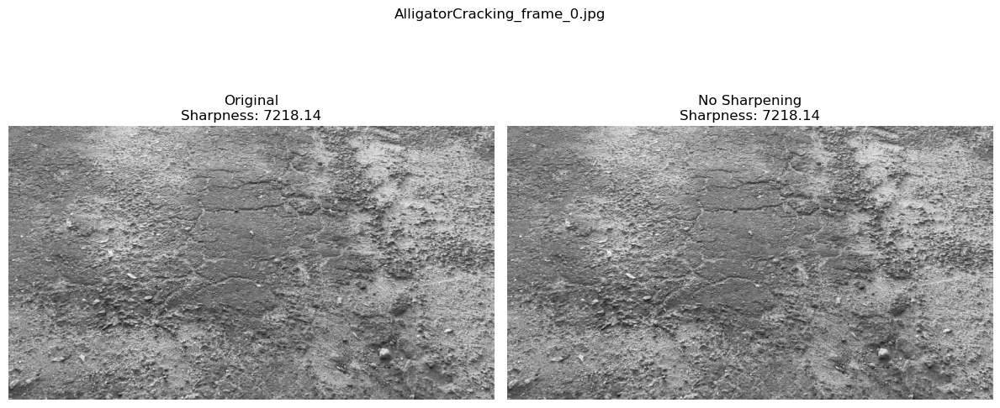

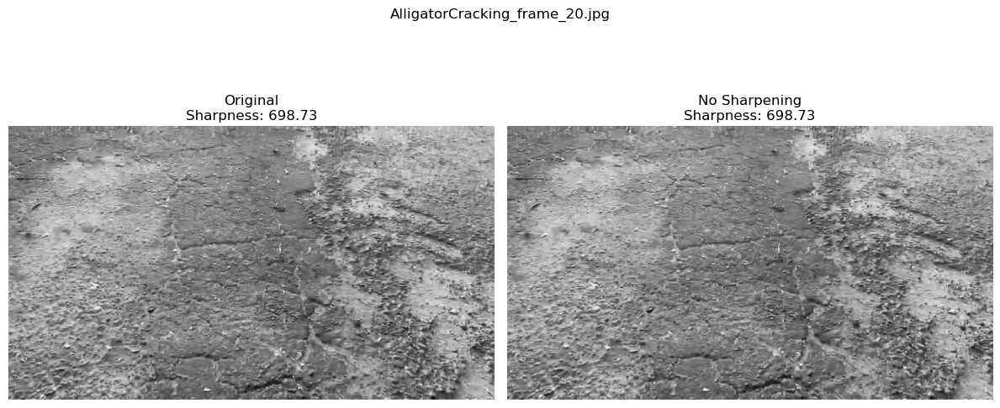

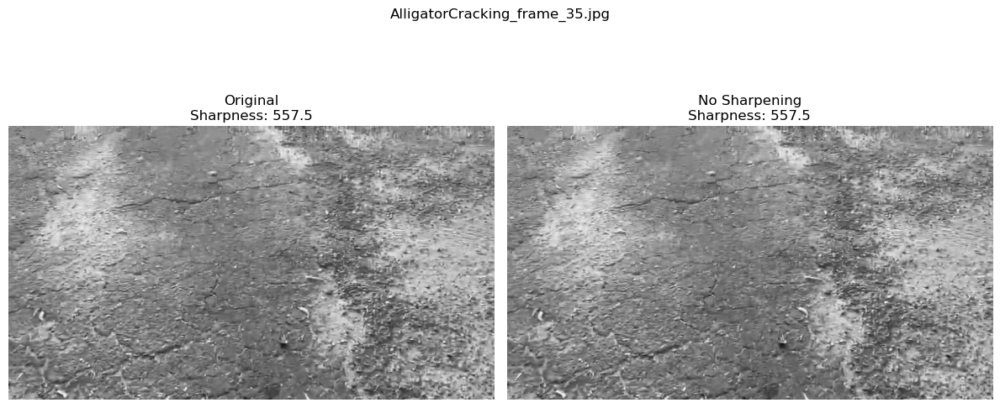

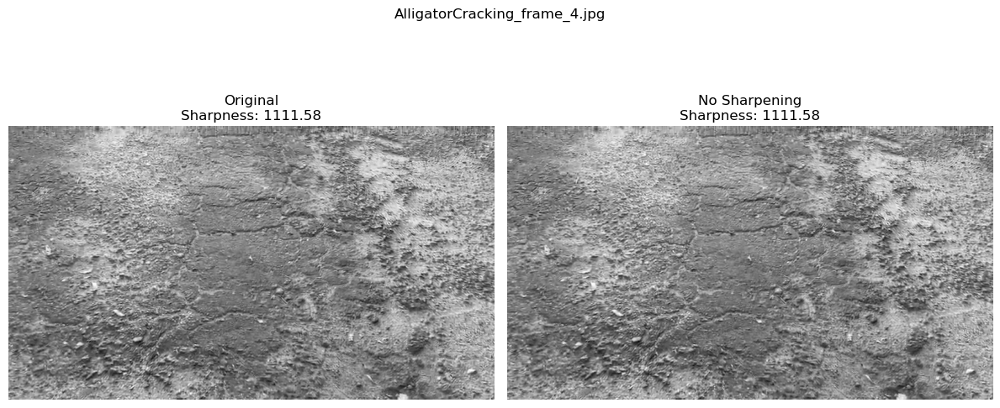

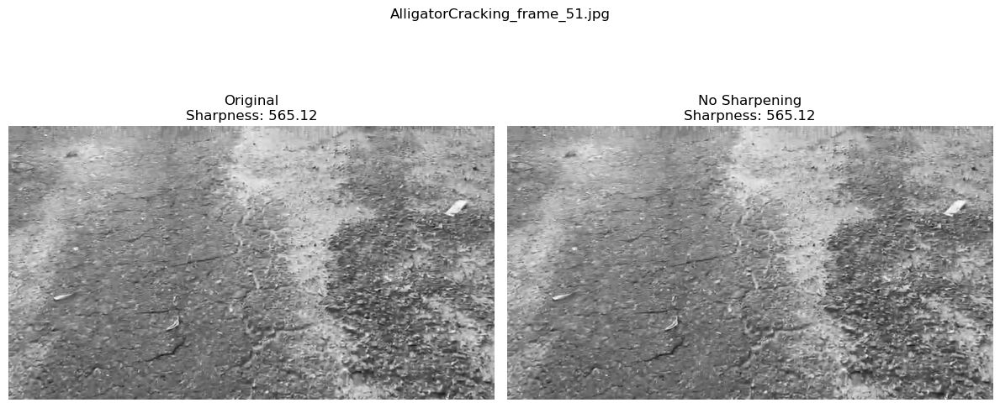

...

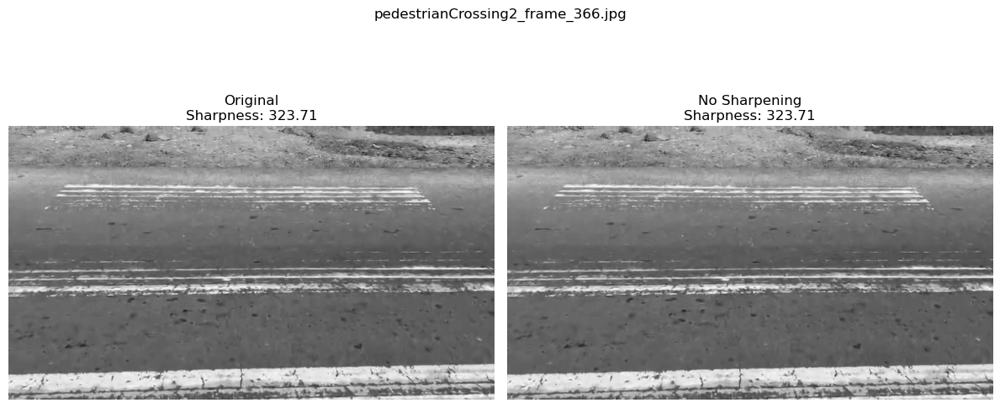

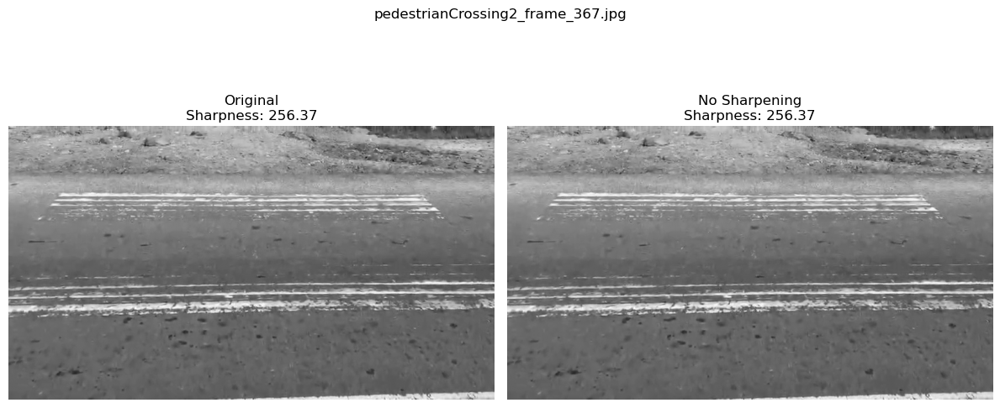

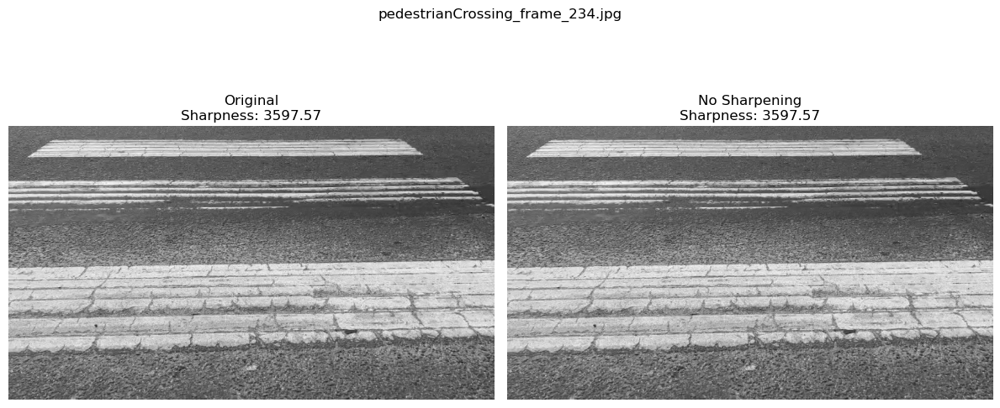

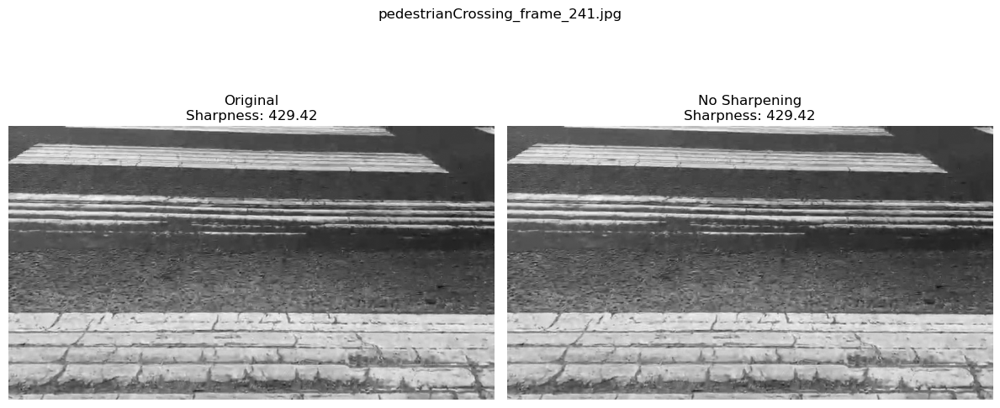

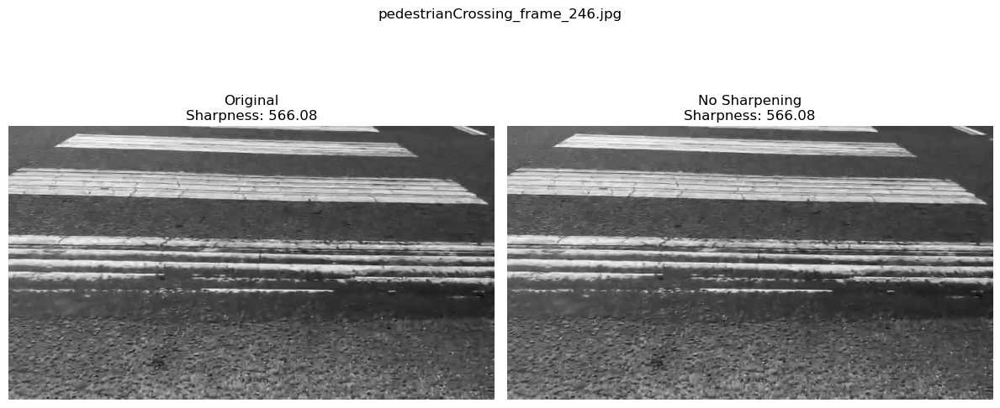


================ BLUR ANALYSIS TABLE ================

Frame                              Status      Sharpness Before  Sharpness After   Improved    
-----------------------------------------------------------------------------------------------
AlligatorCracking_frame_0.jpg      Clear       7218.14           7218.14           No          
AlligatorCracking_frame_20.jpg     Clear       698.73            698.73            No          
AlligatorCracking_frame_35.jpg     Clear       557.5             557.5             No          
AlligatorCracking_frame_4.jpg      Clear       1111.58           1111.58           No          
AlligatorCracking_frame_51.jpg     Clear       565.12            565.12            No          
AlligatorCracking_frame_9.jpg      Clear       841.73            841.73            No          
EdgeCracking3_frame_72.jpg         Clear       568.86            568.86            No          
EdgeCracking4_frame_123.jpg        Clear       684.6             684.6          

In [1]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt

frames_folder = "frames"

def detect_blur(gray):
    return cv2.Laplacian(gray, cv2.CV_64F).var()


def sharpen_image(gray):
    kernel = np.array([[0, -1, 0],
                       [-1, 5,-1],
                       [0, -1, 0]])
    return cv2.filter2D(gray, -1, kernel)

def show_results(original, processed, file_name, blur_before, blur_after, status):

    plt.figure(figsize=(12,6))

    plt.subplot(1,2,1)
    plt.imshow(original, cmap="gray")
    plt.title(f"Original\nSharpness: {round(blur_before,2)}")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(processed, cmap="gray")
    plt.title(f"{status}\nSharpness: {round(blur_after,2)}")
    plt.axis("off")

    plt.suptitle(file_name)
    plt.tight_layout()
    plt.show()


frame_files = sorted(os.listdir(frames_folder))

display_count = 0
max_display = 33

results_table = []


for file in frame_files:

    if not file.lower().endswith((".jpg", ".png", ".jpeg")):
        continue

    path = os.path.join(frames_folder, file)
    img = cv2.imread(path)

    if img is None:
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    blur_before = detect_blur(gray)

    if blur_before < 100:
        is_blurry = True
        blur_level = "Blurry"
    else:
        is_blurry = False
        blur_level = "Clear"


    if is_blurry:
        processed = sharpen_image(gray)
        status = "Sharpened"
    else:
        processed = gray.copy()
        status = "No Sharpening"

    blur_after = detect_blur(processed)

    improvement = "Yes" if blur_after > blur_before else "No"


    results_table.append([
        file,
        blur_level,
        round(blur_before,2),
        round(blur_after,2),
        improvement
    ])


    if display_count < max_display:
        show_results(gray, processed, file, blur_before, blur_after, status)
        display_count += 1


print("\n================ BLUR ANALYSIS TABLE ================\n")

col_widths = [35, 12, 18, 18, 12]

header = ["Frame", "Status", "Sharpness Before", "Sharpness After", "Improved"]

def format_row(row, widths):
    formatted = ""
    for i, item in enumerate(row):
        item = str(item)
        if i == 0 and len(item) > widths[i]:
            item = item[:widths[i]-3] + "..."
        formatted += item.ljust(widths[i])
    return formatted

print(format_row(header, col_widths))
print("-" * sum(col_widths))

for row in results_table:
    print(format_row(row, col_widths))

print("\nBlur Detection & Sharpening Completed ")